# Blackbody vs NewEra star

The pipeline's star is the NewEra model atmosphere (Hauschildt et al. 2025) at each host's $T_{\rm eff}$, log g and [Fe/H] (built in `inputs/stellar_model/NewEra/build_newera.ipynb`). The stellar SED enters only the normalisation of the thermal emission and `T_bright`, so every thermal curve changes by one factor per star and band, $k = S_{\rm BB}/S_{\rm NewEra}$. This notebook runs the same analyses with a blackbody and with the NewEra star (`stellar_model`) and checks the consequences: thermal depths scale by $k$, $A_B$ biases stay, the Fisher $\sigma$ scales as $1/k$, and `T_bright` of a measured depth depends on the star.

In [1]:
import numpy as np
import warnings
import contextlib, io
import pandas as pd
import matplotlib.pyplot as plt
with contextlib.redirect_stdout(io.StringIO()):          # mute "no spidermanrc file detected"
    import fspiderman
from hyperphase.defaults import DEFAULT_A, DEFAULT_A_B, DEFAULT_N_BINS, DEFAULT_N_LA, DEFAULT_N_LO, DEFAULT_N_ORBITS, DEFAULT_U, DEFAULT_U_BOL
from hyperphase.model import ConstantBandAlbedo, FittingConfig
from hyperphase.phasecurve import thermal_PhaseCurve
from hyperphase.stellar import planck_spectrum, spidergrid_value, STEFAN_BOLTZMANN, stellar_spectrum, stellar_spidergrid, T_bright
from hyperphase.bands import filter_lambda, filter_loc
from hyperphase.bias.detectors import instrument_key
from hyperphase.bias.tables import instrument_retrievals
from hyperphase.plotting.bias import plot_instrument_retrievals, retrieval_ylim
from hyperphase.plotting.style import INSTRUMENT_COLORS, set_plot_style
from hyperphase.targets import hi_planets_by_name
from hyperphase.paper import JWST_RETRIEVALS, PAPER_PLANETS
from hyperphase.newera import cube_bins, rebin
warnings.filterwarnings("ignore", message="A worker stopped while some jobs were given to the executor", module="joblib")   # loky replaces a worker whose memory grew (SPIDERMAN's allocator) and warns; its jobs are rerun, the results are unaffected

set_plot_style()

In [2]:
# The two stellar SEDs compared (label -> stellar_model)
MODELS = {"blackbody star": "blackbody", "NewEra star": "newera"}
BB, NE = MODELS

planet = hi_planets_by_name("TOI-2431 b")   # target of the per-instrument sections
INSTRUMENTS = JWST_RETRIEVALS   # the JWST bands singly, plus one joint fit of the two NIRSpec arrays (the tuple)
SINGLE = [ins for ins in INSTRUMENTS if isinstance(ins, str)]   # single detectors: the per-band quantities (k, curves, depths)

# baseline settings (hyperphase/defaults.py)
A_B_true = DEFAULT_A_B
A_model = ConstantBandAlbedo(DEFAULT_A)   # band-integrated albedo A of the reflected light, independent of A_B
u, u_bol = DEFAULT_U, DEFAULT_U_BOL           # transit and irradiance limb darkening
n_bins, n_orbits = DEFAULT_N_BINS, DEFAULT_N_ORBITS
kw = dict(n_lo=DEFAULT_N_LO, n_la=DEFAULT_N_LA)

# one cfg per stellar model; instrument_retrievals / instrument_cfg swap in each band, the stellar grid follows (FittingConfig.__post_init__)
cfgs = {lab: FittingConfig(planet=planet, filter_path=filter_loc("MIRI/LRS"), l1=filter_lambda("MIRI/LRS")[0], l2=filter_lambda("MIRI/LRS")[1], A_=A_model,
                           sigma_1min=100., n_orbits=n_orbits, n_bins=n_bins, reflected=True, u_bol=u_bol, u=u, stellar_model=m)
        for lab, m in MODELS.items()}
short = lambda ins: instrument_key(ins).replace("JWST_NIRSpec.G395H_", "").replace("MIRI/", "") if isinstance(ins, str) else "+".join(short(d) for d in ins)

# depth multiplier k = S_BB / S_NewEra of a host in one band, at its T_eff, from SPIDERMAN's own spline through the two stellar grids
def k_factor(pl, instrument):
    lr, fp = filter_lambda(instrument), filter_loc(instrument)
    g = {m: stellar_spidergrid(lr, fp, pl.logg, pl.feh, stellar_model=m) for m in MODELS.values()}
    return spidergrid_value(g["blackbody"], pl.T2_eff) / spidergrid_value(g["newera"], pl.T2_eff)

fmt = lambda v: f"{v:.4g}"   # number format of the comparison tables

## 1. The two stellar spectra

NewEra surface flux against $\pi B_\lambda(T_{\rm eff})$ and their ratio, for the target's host and an M dwarf (thin: R = 5000; thick: binned to R = 300; shaded: the bands). The model has a near-IR excess and a mid-IR deficit, larger for the cooler star.

In [3]:
SPEC_HOSTS = {planet.name: planet, "TRAPPIST-1 b": hi_planets_by_name("TRAPPIST-1 b")}
edges_nm, centres_nm = cube_bins(R=300, lo=650., hi=28000.)   # display binning only (flux-conserving)
lam_b = centres_nm * 1e-9
spec = {}
for nm, pl in SPEC_HOSTS.items():
    w, I = stellar_spectrum(pl.T2_eff, pl.logg, pl.feh, "newera")
    F_ne, F_bb = np.pi * I, np.pi * planck_spectrum(w, pl.T2_eff)
    spec[nm] = dict(w=w, F_ne=F_ne, Fb_ne=rebin(w, F_ne, edges_nm * 1e-9), Fb_bb=rebin(w, F_bb, edges_nm * 1e-9))
    x = np.geomspace(0.6e-6, 28.5e-6, 20000)
    outside = 1. - np.trapezoid(np.pi * planck_spectrum(x, pl.T2_eff), x) / (STEFAN_BOLTZMANN * pl.T2_eff ** 4)
    print(f"{nm} host: T_eff {pl.T2_eff:.0f} K, log g {pl.logg:.2f}, [Fe/H] {pl.feh:+.2f}; NewEra / blackbody flux over 0.6-28.5 um: {np.trapezoid(F_ne, w) / np.trapezoid(F_bb, w):.4f}; "
          f"blackbody flux outside 0.6-28.5 um: {outside:.3f}")

TOI-2431 b host: T_eff 4109 K, log g 4.68, [Fe/H] -0.02; NewEra / blackbody flux over 0.6-28.5 um: 1.0488; blackbody flux outside 0.6-28.5 um: 0.154
TRAPPIST-1 b host: T_eff 2566 K, log g 5.24, [Fe/H] +0.05; NewEra / blackbody flux over 0.6-28.5 um: 1.0126; blackbody flux outside 0.6-28.5 um: 0.016


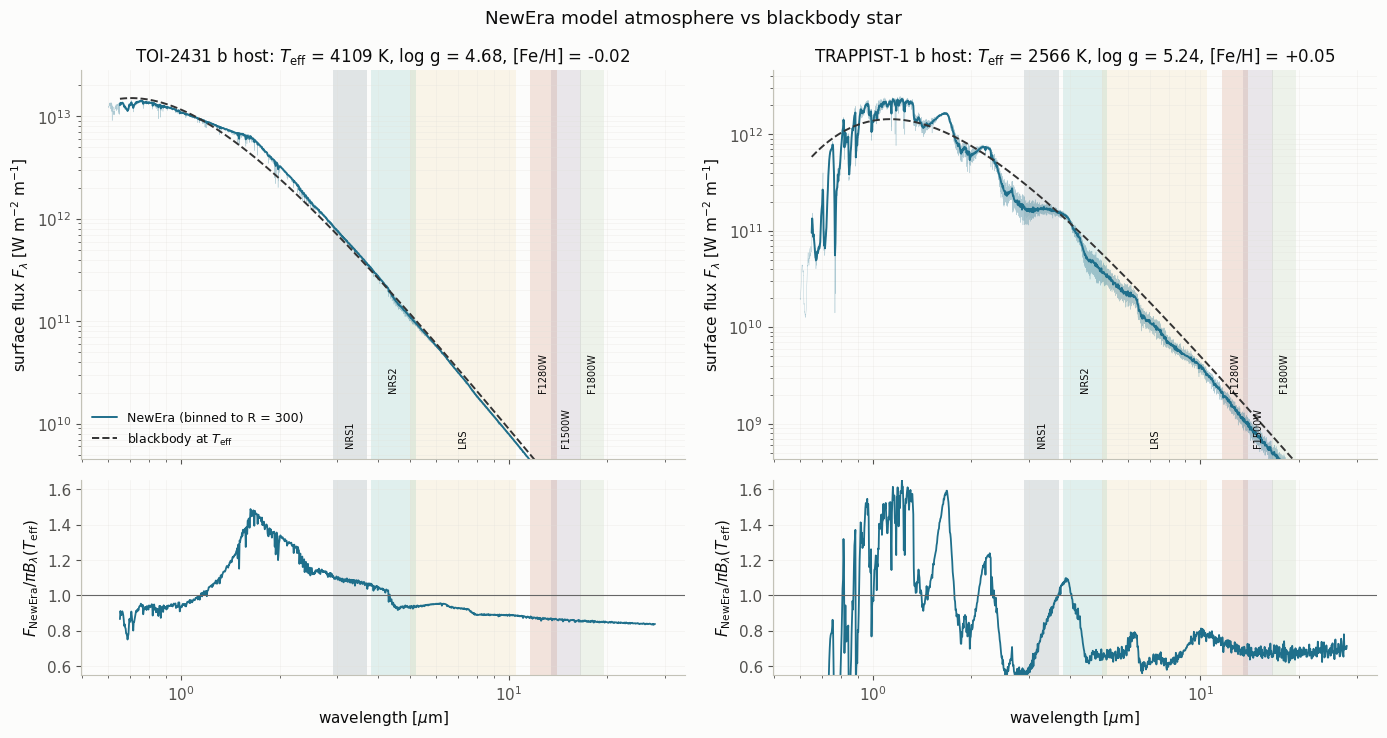

In [4]:
fig, axes = plt.subplots(2, len(spec), figsize=(14, 7.5), sharex=True, gridspec_kw=dict(height_ratios=(2, 1)))
for j, (nm, s) in enumerate(spec.items()):
    ax, ax_r = axes[0, j], axes[1, j]
    ax.plot(s["w"] * 1e6, s["F_ne"], color="#1f6f8b", lw=0.3, alpha=0.35)
    ax.plot(lam_b * 1e6, s["Fb_ne"], color="#1f6f8b", lw=1.4, label="NewEra (binned to R = 300)")
    ax.plot(lam_b * 1e6, s["Fb_bb"], "--", color="#333333", lw=1.4, label=r"blackbody at $T_{\rm eff}$")
    ax_r.plot(lam_b * 1e6, s["Fb_ne"] / s["Fb_bb"], color="#1f6f8b", lw=1.3)
    ax_r.axhline(1., color="0.4", lw=0.8)
    for k_, ins in enumerate(SINGLE):
        l1, l2 = filter_lambda(ins)
        for a in (ax, ax_r): a.axvspan(l1 * 1e6, l2 * 1e6, color=INSTRUMENT_COLORS[k_ % len(INSTRUMENT_COLORS)], alpha=0.13, lw=0)
        ax.text(np.sqrt(l1 * l2) * 1e6, 0.03 + 0.14 * (k_ % 2), short(ins), transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=7, rotation=90)   # staggered: adjacent bands overlap
    pl = SPEC_HOSTS[nm]
    ax.set(xscale="log", yscale="log", ylim=(s["Fb_bb"].max() * 3e-4, s["Fb_ne"].max() * 2.), ylabel=r"surface flux $F_\lambda$ [W m$^{-2}$ m$^{-1}$]",
           title=rf"{nm} host: $T_{{\rm eff}}$ = {pl.T2_eff:.0f} K, log g = {pl.logg:.2f}, [Fe/H] = {pl.feh:+.2f}")
    ax_r.set(xlabel=r"wavelength [$\mu$m]", ylabel=r"$F_{\rm NewEra} / \pi B_\lambda(T_{\rm eff})$", ylim=(0.55, 1.65))
    for a in (ax, ax_r): a.grid(alpha=0.3, which="both")
axes[0, 0].legend(fontsize=9)
fig.suptitle("NewEra model atmosphere vs blackbody star")
fig.tight_layout()
plt.show()

## 2. The depth multiplier $k$ for every host and band

$k$ at the host's $T_{\rm eff}$ from SPIDERMAN's spline through the two stellar grids: a thermal depth with the NewEra star is $k$ times the blackbody-star value. In the mid-IR $k > 1$ (H$^-$ free-free opacity puts the photosphere higher and cooler), growing towards cool hosts.

In [5]:
HOSTS = [*PAPER_PLANETS, "LHS 3844 b", "TRAPPIST-1 b"]   # the planets of the paper and two cool hosts
hosts = hi_planets_by_name(HOSTS)

k_tab = pd.DataFrame([{"host": nm, "T_eff": pl.T2_eff, "logg": pl.logg, "[Fe/H]": pl.feh, **{short(ins): k_factor(pl, ins) for ins in SINGLE}} for nm, pl in hosts.items()]).sort_values("T_eff")
print(k_tab.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

        host    T_eff  logg  [Fe/H]  NRS1  NRS2   LRS  F1280W  F1500W  F1800W
TRAPPIST-1 b 2566.000 5.240   0.052 1.282 1.199 1.484   1.418   1.474   1.481
  LHS 3844 b 3080.000 5.070   0.220 1.102 1.038 1.175   1.200   1.209   1.206
  TOI-2431 b 4109.000 4.680  -0.020 0.924 1.008 1.086   1.150   1.162   1.173
    K2-141 b 4599.000 4.620  -0.060 0.936 1.039 1.112   1.176   1.188   1.201
 Kepler-78 b 5058.000 4.550  -0.180 0.974 1.066 1.130   1.188   1.199   1.211
 TOI-1798.02 5106.000 4.572   0.073 0.974 1.068 1.130   1.188   1.199   1.211
    K2-131 b 5120.000 4.620  -0.040 0.976 1.068 1.131   1.188   1.200   1.212
    55 Cnc e 5172.000 4.430   0.350 0.975 1.073 1.131   1.187   1.198   1.210
   TOI-561 b 5372.000 4.500  -0.400 1.000 1.080 1.141   1.195   1.205   1.215
  TOI-1444 b 5430.000 4.490   0.130 0.997 1.083 1.140   1.193   1.203   1.215
  TOI-2260 b 5534.000 4.620   0.220 1.002 1.085 1.141   1.194   1.203   1.215
  HD 80653 b 5959.000 4.342   0.255 1.031 1.100 1.153   1.204   

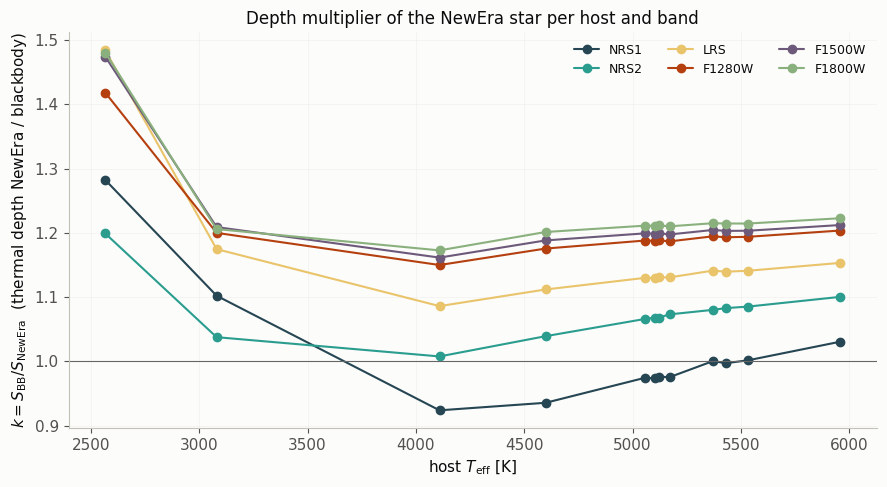

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
for k_, ins in enumerate(SINGLE):
    ax.plot(k_tab["T_eff"], k_tab[short(ins)], "o-", color=INSTRUMENT_COLORS[k_ % len(INSTRUMENT_COLORS)], label=short(ins))
ax.axhline(1, color="0.4", lw=0.8)
ax.set(xlabel=r"host $T_{\rm eff}$ [K]", ylabel=r"$k = S_{\rm BB} / S_{\rm NewEra}$  (thermal depth NewEra / blackbody)", title="Depth multiplier of the NewEra star per host and band")
ax.grid(alpha=0.3); ax.legend(ncol=3, fontsize=9)
fig.tight_layout()
plt.show()

## 3. Occultation depths and brightness temperatures

The thermal depth with each star, their ratio ($= k$), and brightness temperatures: each model depth gives the same `T_bright` with its own star, while the blackbody-star depth read as a measurement with the NewEra star does not.

In [7]:
rows = []
for ins in SINGLE:
    lr, fp = filter_lambda(ins), filter_loc(ins)
    d = {lab: thermal_PhaseCurve(planet, lr, t=np.array([0.5 * planet.period]), u_bol=u_bol, A_B=A_B_true, filter_path=fp, insolation_model="hyperillum", include_transit=False, spman="normal", stellar_model=m)[2]
         for lab, m in MODELS.items()}
    rows.append(dict(band=short(ins), depth_BB=d[BB], depth_NE=d[NE], ratio=d[NE] / d[BB],
                     T_bright_BB=T_bright(d[BB], planet, lr, filter_path=fp, stellar_model="blackbody"), T_bright_NE=T_bright(d[NE], planet, lr, filter_path=fp, stellar_model="newera"),
                     T_bright_BBdepth_with_NE=T_bright(d[BB], planet, lr, filter_path=fp, stellar_model="newera")))
print(f"{planet.name}, hyperillumination model, A_B = {A_B_true}: thermal depths [ppm] and brightness temperatures [K]")
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3f}" if abs(v) < 10 else f"{v:.1f}"))

TOI-2431 b, hyperillumination model, A_B = 0.2: thermal depths [ppm] and brightness temperatures [K]
  band  depth_BB  depth_NE  ratio  T_bright_BB  T_bright_NE  T_bright_BBdepth_with_NE
  NRS1     163.8     151.3  0.924       2384.9       2384.9                    2474.1
  NRS2     185.8     187.3  1.008       2380.3       2380.3                    2370.6
   LRS     213.9     232.3  1.086       2375.6       2375.6                    2249.4
F1280W     235.6     270.9  1.150       2373.7       2373.7                    2127.2
F1500W     239.6     278.3  1.162       2373.5       2373.5                    2101.9
F1800W     243.3     285.4  1.173       2373.2       2373.2                    2076.5


## 4. Retrieved $A_B$ per instrument

The hyperillumination truth fitted on every instrument (`instrument_retrievals`, the planet's own PandExo noise) with the $A_B$-only and the joint $A_B$ + $F$ model, for both stars. The bias is the same for both; the Fisher $\sigma$ scales as $1/k$ (`sigma_ratio`).

In [8]:
tab_AB = {BB: instrument_retrievals(cfgs[BB], planet, INSTRUMENTS, A_B_true, **kw)}
sigma_inst = tab_AB[BB].attrs["sigma_1min"]   # PandExo noise, independent of the stellar SED: reused for the NewEra star
tab_AB[NE] = instrument_retrievals(cfgs[NE], planet, INSTRUMENTS, A_B_true, sigma_1min=sigma_inst, **kw)
tab_J = {lab: instrument_retrievals(cfgs[lab], planet, INSTRUMENTS, A_B_true, redist=True, sigma_1min=sigma_inst, **kw) for lab in MODELS}

def compare(tabs, key, cols):
    a, b = (tabs[lab].set_index(key) for lab in (BB, NE))
    out = pd.DataFrame({f"{c}_BB": a[c] for c in cols} | {f"{c}_NE": b[c] for c in cols})
    out = out[[f"{c}_{s}" for c in cols for s in ("BB", "NE")]]
    return out

for name, tabs in (("A_B-only fit", tab_AB), ("joint A_B + F fit", tab_J)):
    cols = ["bias_A_B", "sigma_A_B", "bias_sigma", "verdict"] + (["F_fit", "sigma_F"] if "joint" in name else [])
    cmp_ = compare(tabs, "instrument", cols)
    cmp_.insert(2, "d_bias", cmp_["bias_A_B_NE"] - cmp_["bias_A_B_BB"]); cmp_.insert(5, "sigma_ratio", cmp_["sigma_A_B_NE"] / cmp_["sigma_A_B_BB"])
    print(f"--- {name} ({planet.name}, A_B_true = {A_B_true}, {n_orbits} orbits)")
    print(cmp_.rename(index=short).to_string(float_format=fmt))
    print()

--- A_B-only fit (TOI-2431 b, A_B_true = 0.2, 5 orbits)
            bias_A_B_BB  bias_A_B_NE     d_bias  sigma_A_B_BB  sigma_A_B_NE  sigma_ratio  bias_sigma_BB  bias_sigma_NE        verdict_BB        verdict_NE
instrument                                                                                                                                                
NRS1           -0.03862     -0.03873 -0.0001105       0.03192       0.03455        1.083           1.21          1.121  needs hyperillum  needs hyperillum
NRS2           -0.04778     -0.04777  1.029e-05       0.04183       0.04151       0.9924          1.142          1.151  needs hyperillum  needs hyperillum
NRS1+NRS2      -0.04205     -0.04245 -0.0004061       0.02537       0.02655        1.047          1.657          1.599  needs hyperillum  needs hyperillum
LRS            -0.05989     -0.05978  0.0001158       0.05765       0.05308       0.9207          1.039          1.126  needs hyperillum  needs hyperillum
F1280W        

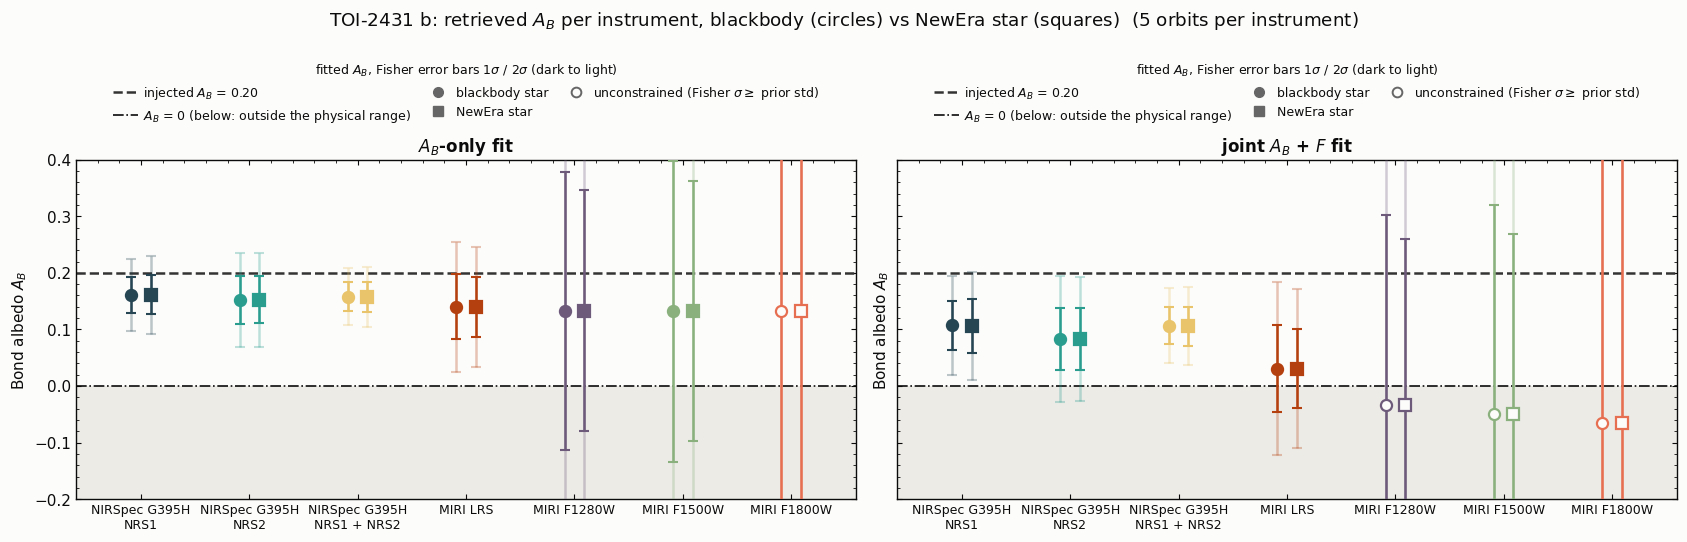

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5), sharey=True)
ylim = retrieval_ylim([*tab_AB.values(), *tab_J.values()])   # one range for both panels (shared y axis), so both draw the A_B < 0 band
plot_instrument_retrievals(tab_AB, ax=axes[0], ylim=ylim, title=r"$A_B$-only fit")
plot_instrument_retrievals(tab_J, ax=axes[1], ylim=ylim, title=r"joint $A_B$ + $F$ fit")
fig.suptitle(f"{planet.name}: retrieved $A_B$ per instrument, blackbody (circles) vs NewEra star (squares)  ({n_orbits} orbits per instrument)")
fig.tight_layout()
plt.show()